# Прогнозування відтоку клієнтів телекомунікаційної компанії
Фінальний проєкт GoIT (Data Science / ML). Ноутбук містить: EDA, обробку даних, вибір моделі, оцінку результатів та перевірку інтерфейсу прогнозування.
Код обробки й навчання лежить у `src/`, тут він використовується й пояснюється.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from src.preprocessing import load_data, split_xy, add_features, RAW_FEATURES, TARGET
sns.set_theme(style="whitegrid")
df = load_data()
print(df.shape, "дублікатів рядків:", df.duplicated().sum())
df.head()

(72274, 11) дублікатів рядків: 0


,id,is_tv_subscriber,is_movie_package_subscriber,subscription_age,bill_avg,reamining_contract,service_failure_count,download_avg,upload_avg,download_over_limit,churn
0,15,1,0,11.95,25,0.14,0,8.4,2.3,0,0
1,18,0,0,8.22,0,NaN,0,0.0,0.0,0,1
2,23,1,0,8.91,16,0.00,0,13.7,0.9,0,1
3,27,0,0,6.87,21,NaN,1,0.0,0.0,0,1
4,34,0,0,6.39,0,NaN,0,0.0,0.0,0,1


## 1. EDA

In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,72274.0,846318.243462,489102.168744,15.00,422216.50,847784.00,1269562.00,1689744.00
is_tv_subscriber,72274.0,0.815259,0.388090,0.00,1.00,1.00,1.00,1.00
is_movie_package_subscriber,72274.0,0.334629,0.471864,0.00,0.00,0.00,1.00,1.00
subscription_age,72274.0,2.450051,2.034990,-0.02,0.93,1.98,3.30,12.80
bill_avg,72274.0,18.942483,13.215386,0.00,13.00,19.00,22.00,406.00
reamining_contract,50702.0,0.716039,0.697102,0.00,0.00,0.57,1.31,2.92
service_failure_count,72274.0,0.274234,0.816621,0.00,0.00,0.00,0.00,19.00
download_avg,71893.0,43.689911,63.405963,0.00,6.70,27.80,60.50,4415.20
upload_avg,71893.0,4.192076,9.818896,0.00,0.50,2.10,4.80,453.30
download_over_limit,72274.0,0.207613,0.997123,0.00,0.00,0.00,0.00,7.00


In [3]:
print('Частка відтоку:', round(df.churn.mean(), 3))
print(df.isna().sum()[lambda s: s > 0])

Частка відтоку: 0.554
reamining_contract    21572
download_avg            381
upload_avg              381
dtype: int64


**Висновки по даних**
- Класи майже збалансовані (≈55% пішли), тож Accuracy інформативна, але все одно дивимось Precision/Recall/F1.
- Пропуски: `reamining_contract` (~30%) та `download_avg`/`upload_avg` (381 рядок).
- Усі ознаки числові (категоріальних немає), тому One-Hot / Label Encoding не потрібні.
- Дублікатів немає.

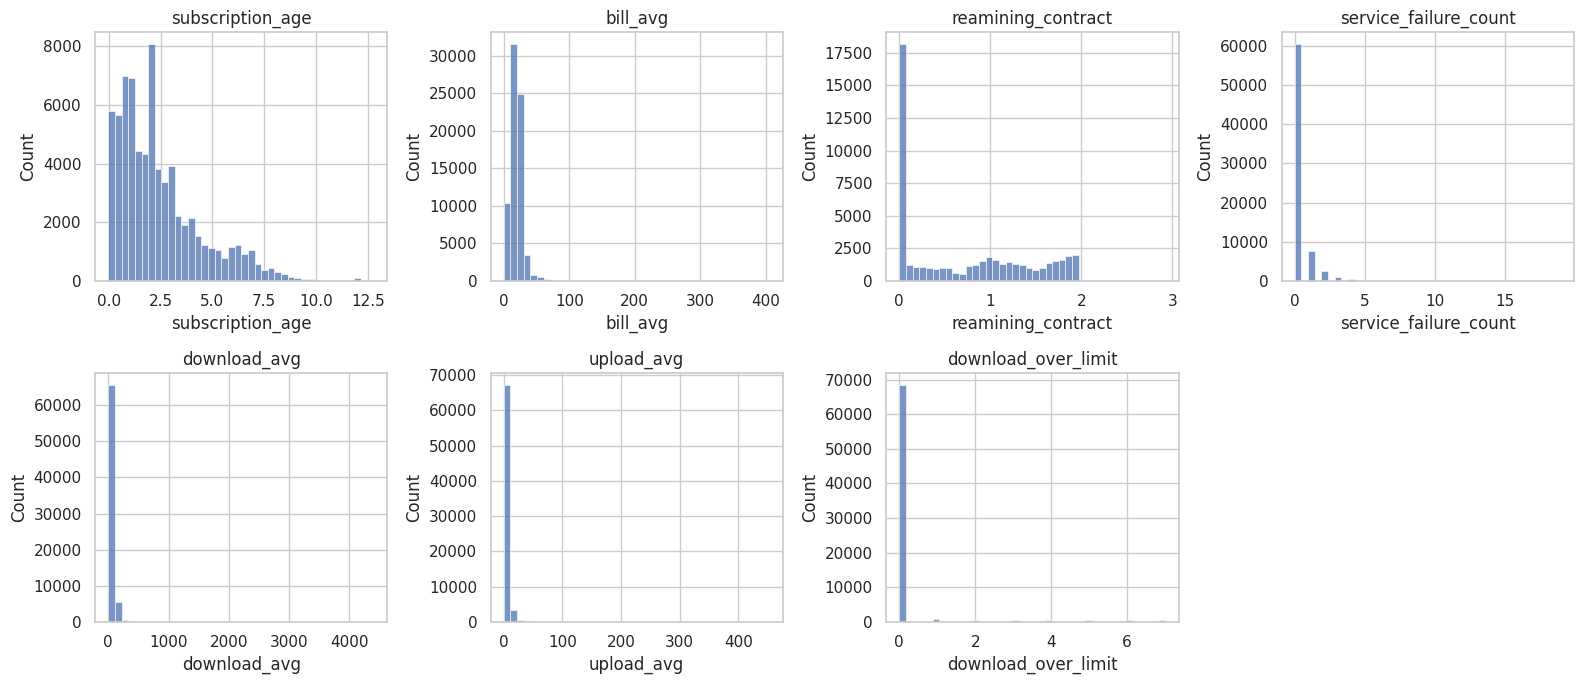

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
num = ["subscription_age", "bill_avg", "reamining_contract", "service_failure_count",
       "download_avg", "upload_avg", "download_over_limit"]
for ax, c in zip(axes.ravel(), num):
    sns.histplot(df[c].dropna(), bins=40, ax=ax); ax.set_title(c)
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

Розподіли `bill_avg`, `download_avg`, `upload_avg` сильно скошені, є екстремальні викиди (download до 4415, bill до 406). Також `subscription_age` має одне від'ємне значення (−0.02).

In [5]:
print("Від'ємний вік підписки:", (df.subscription_age < 0).sum())
print(df[["bill_avg", "download_avg", "upload_avg"]].quantile([.5, .99, .999, 1]))

Від'ємний вік підписки: 1
       bill_avg  download_avg  upload_avg
0.500      19.0       27.8000      2.1000
0.990      59.0      237.2000     35.2080
0.999     162.0      562.8216    132.9484
1.000     406.0     4415.2000    453.3000


### Кореляції

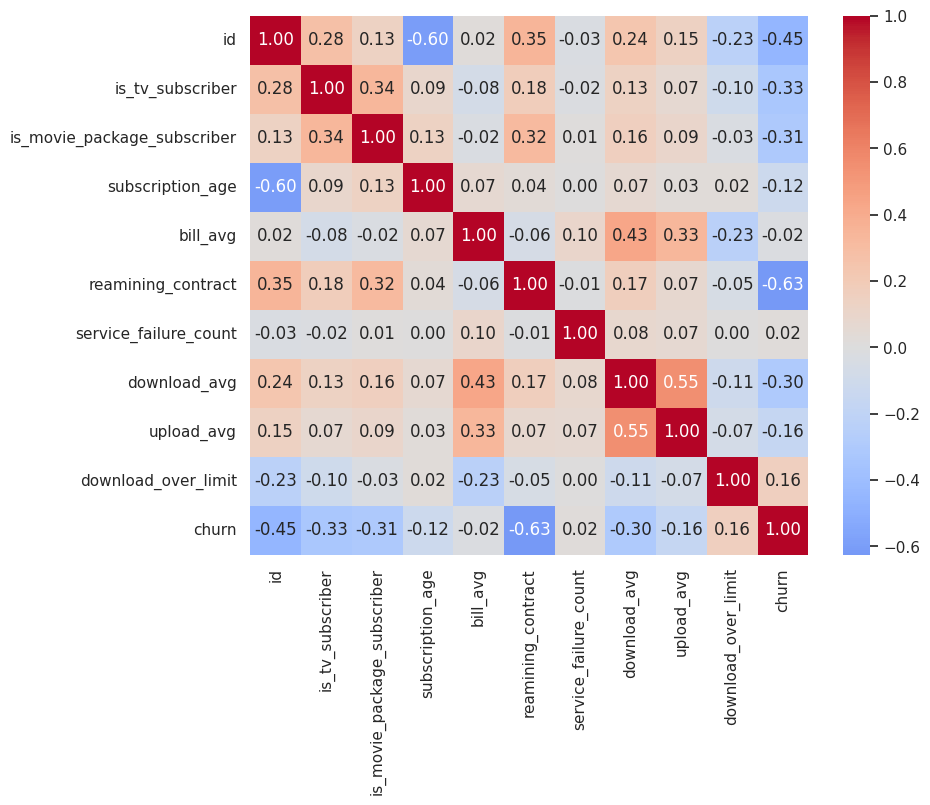

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.show()

Найсильніший зв'язок із відтоком має `reamining_contract` (−0.63). **Але `id` має кореляцію −0.45 з `churn`** — це ідентифікатор, і така залежність є артефактом упорядкування даних, а не реальною закономірністю.
Модель, що використала б `id`, була б неправдоподібно хорошою і марною для нових клієнтів, тому `id` **виключено** з ознак.

In [7]:
d = df.copy()
d["contract_status"] = pd.cut(d.reamining_contract.fillna(-1), [-2, -0.5, 0, 0.5, 1, 3],
    labels=["немає контракту", "закінчився (0)", "0–0.5 р.", "0.5–1 р.", ">1 р."])
print(d.groupby("contract_status", observed=True).churn.agg(["mean", "size"]).round(3))
print()
print("Пропуск у download_avg -> churn:", df[df.download_avg.isna()].churn.mean())
print(df.groupby("is_tv_subscriber").churn.mean().round(3))
print(df.groupby("is_movie_package_subscriber").churn.mean().round(3))

                  mean   size
contract_status              
немає контракту  0.914  21572
закінчився (0)   0.996  16363
0–0.5 р.         0.152   8063
0.5–1 р.         0.117   7393
>1 р.            0.103  18883

Пропуск у download_avg -> churn: 0.0
is_tv_subscriber
0    0.896
1    0.477
Name: churn, dtype: float64
is_movie_package_subscriber
0    0.662
1    0.339
Name: churn, dtype: float64


**Ключові закономірності**
- Немає контракту → 91% відтоку; контракт щойно закінчився (0 років) → **99.6%** відтоку; залишилось понад 0.5 року → лише ~10–15%.
- Клієнти без ТБ-підписки йдуть значно частіше (90% проти 48%), так само без пакета фільмів (66% проти 34%).
- Чим менше трафіку, тим вища ймовірність відтоку (мало користуються — легко йдуть).
- `service_failure_count` майже не впливає на відтік (55% при 0 збоїв проти 59% при 2) — слабка ознака.
- Усі 381 клієнти без даних про трафік залишились (churn = 0) — пропуск тут сам є сигналом.

## 2. Попередня обробка (`src/preprocessing.py`)
| Проблема | Рішення | Обґрунтування |
|---|---|---|
| Пропуски `reamining_contract` | заповнити 0 + прапорці `no_contract`, `contract_ended` | пропуск = «немає контракту», це інформативно (91% відтоку); видалення втратило б 30% даних |
| Пропуски `download_avg`/`upload_avg` | прапорець `no_usage_data` + медіана (в `SimpleImputer`) | у цих клієнтів відтік 0%; медіана стійка до викидів |
| Від'ємний `subscription_age` | `clip(lower=0)` | некоректне значення |
| Скошені `bill_avg`, `download_avg`, `upload_avg` | `log1p` | зменшує вплив викидів, важливо для лінійної моделі |
| Різні масштаби | `StandardScaler` | вимога ТЗ (стандартизація) |
| `id` | видалено | ідентифікатор, витік |
| Категоріальні | не потрібні | усі ознаки числові |

Імпутер і скейлер входять у `Pipeline`, тож під час крос-валідації вони навчаються лише на train-фолдах — **витоку даних немає**.

In [8]:
X, y = split_xy(df)
add_features(X).describe().T[["count", "mean", "std", "min", "max"]].round(3)

,count,mean,std,min,max
is_tv_subscriber,72274.0,0.815,0.388,0.0,1.000
is_movie_package_subscriber,72274.0,0.335,0.472,0.0,1.000
subscription_age,72274.0,2.450,2.035,0.0,12.800
bill_avg,72274.0,2.755,0.870,0.0,6.009
reamining_contract,72274.0,0.502,0.670,0.0,2.920
service_failure_count,72274.0,0.274,0.817,0.0,19.000
download_avg,71893.0,2.928,1.604,0.0,8.393
upload_avg,71893.0,1.166,0.888,0.0,6.119
download_over_limit,72274.0,0.208,0.997,0.0,7.000
no_contract,72274.0,0.298,0.458,0.0,1.000


## 3. Моделі та підбір параметрів
Розбиття 80/20 зі стратифікацією (`random_state=42`). Три алгоритми, для кожного — `GridSearchCV` зі стратифікованою 5-fold крос-валідацією, метрика відбору — F1:
- **Logistic Regression** — проста інтерпретована базова модель (параметр `C`);
- **Random Forest** — нелінійний ансамбль (`max_depth`, `min_samples_leaf`);
- **HistGradientBoosting** — градієнтний бустинг (`learning_rate`, `max_depth`).

Навчання виконує `python -m src.train` (займає ≈3 хв), результати збережені у `reports/`.

In [9]:
cmp = pd.read_csv("reports/model_comparison.csv")
cmp.round(4)

,model,cv_f1,accuracy,precision,recall,f1,roc_auc,best_params
0,HistGradientBoosting,0.9484,0.9435,0.9566,0.9408,0.9486,0.9826,"{""learning_rate"": 0.1, ""max_depth"": null, ""max..."
1,RandomForest,0.9452,0.9386,0.9544,0.9337,0.9440,0.9797,"{""max_depth"": 14, ""min_samples_leaf"": 5}"
2,LogisticRegression,0.9399,0.9325,0.9504,0.9266,0.9384,0.9609,"{""C"": 1}"


HistGradientBoosting найкращий за всіма метриками. Різниця між CV F1 (0.9484) та тестовим F1 (0.9486) мінімальна — перенавчання немає.
Лінійна модель уже дає F1 0.938, тобто дані значною мірою лінійно розділимі (завдяки прапорцям контракту), а бустинг додає ≈1 п.п. за рахунок нелінійних взаємодій (особливо видно по ROC-AUC: 0.983 проти 0.961).

## 4. Оцінка результатів

In [10]:
m = json.load(open("reports/metrics.json"))
print("Найкраща модель:", m["best_model"], m["best_params"])
pd.Series(m["test_metrics"]).round(4)

Найкраща модель: HistGradientBoosting {'learning_rate': 0.1, 'max_depth': None, 'max_iter': 200}


accuracy     0.9435
precision    0.9566
recall       0.9408
f1           0.9486
roc_auc      0.9826
dtype: float64

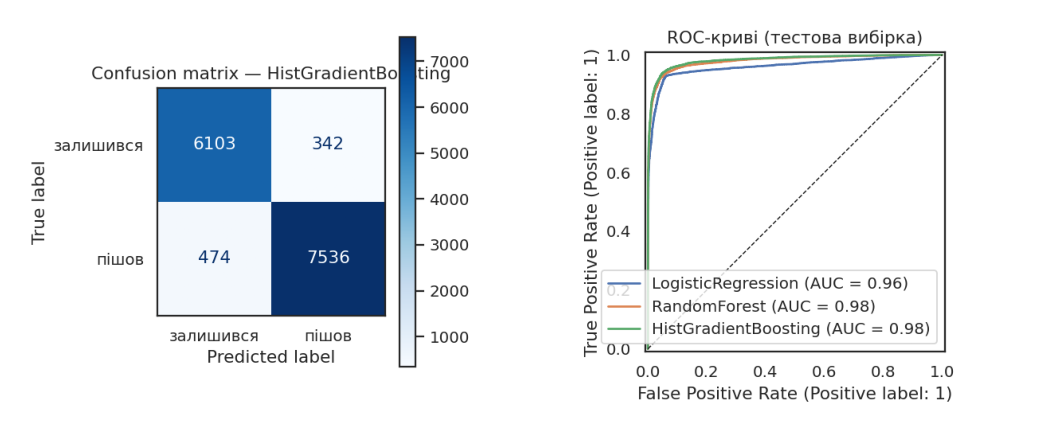

In [11]:
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, f in zip(axes, ["09_confusion_matrix.png", "10_roc_curves.png"]):
    ax.imshow(mpimg.imread("reports/figures/" + f)); ax.axis("off")
plt.tight_layout(); plt.show()

- **Precision 0.957**: із клієнтів, яких модель назвала «ризик відтоку», 95.7% справді пішли.
- **Recall 0.941**: модель знаходить 94.1% усіх клієнтів, що пішли.
- Для бізнесу помилка «пропустили клієнта, що піде» (FN) зазвичай дорожча за «зайвий дзвінок лояльному» (FP), тому порогом можна керувати:

In [12]:
pd.read_csv('reports/threshold_analysis.csv').round(4)

,threshold,accuracy,precision,recall,f1
0,0.3,0.9406,0.9397,0.9541,0.9468
1,0.4,0.9429,0.9492,0.9476,0.9484
2,0.5,0.9435,0.9566,0.9408,0.9486
3,0.6,0.9422,0.9630,0.9315,0.9469
4,0.7,0.9370,0.9695,0.9152,0.9416


Зниження порогу до 0.3–0.4 підвищує Recall (до 0.95) за невеликої втрати Precision; F1 майже не змінюється (0.947–0.949). Для застосунку лишено стандартний поріг 0.5, його можна змінити в `models/metadata.json`.

### Важливість ознак

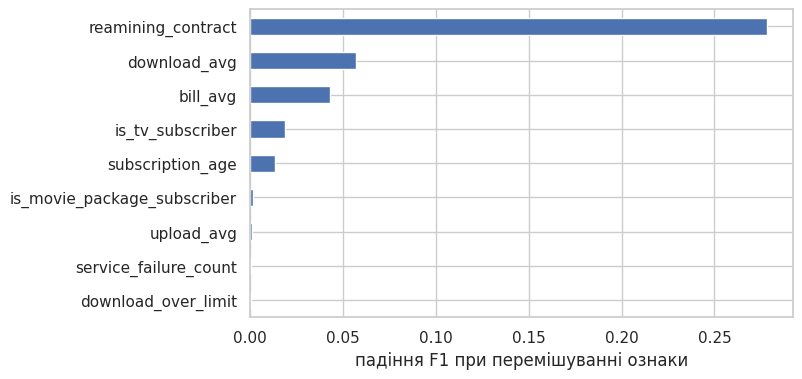

In [13]:
imp = pd.read_csv("reports/feature_importance.csv", index_col=0)["importance"].sort_values()
imp.plot.barh(figsize=(7, 4)); plt.xlabel("падіння F1 при перемішуванні ознаки"); plt.show()

**Інтерпретація**
- Домінує `reamining_contract` (падіння F1 ≈ 0.28) — стан контракту є головним предиктором відтоку.
- Далі `download_avg` та `bill_avg`, потім `is_tv_subscriber` і `subscription_age`.
- `service_failure_count`, `download_over_limit`, `upload_avg` майже не впливають — узгоджується з EDA.
- Бізнес-висновок: найефективніше утримувати клієнтів, у яких контракт закінчується або вже закінчився, пропонуючи пролонгацію/пакети ТБ; клієнти з низьким трафіком — наступна група ризику.

**Обмеження.** (1) Найкращі параметри бустингу лежать на межі сітки (`learning_rate=0.1`, `max_depth=None`), тож розширення сітки могло б дати невеликий приріст. (2) Датасет не містить часової компоненти, тому оцінка стосується випадкового split, а не майбутніх періодів.

## 5. Інтерфейс прогнозування
Форма та API у `app/app.py` (Flask) викликають `src/predict.py`. Нижче — перевірка тієї ж функції.

In [14]:
from src.predict import predict_customer
loyal = dict(is_tv_subscriber=1, is_movie_package_subscriber=1, subscription_age=3, bill_avg=20,
             reamining_contract=1.5, service_failure_count=0, download_avg=60, upload_avg=4, download_over_limit=0)
risky = dict(loyal, is_tv_subscriber=0, is_movie_package_subscriber=0, reamining_contract=None, download_avg=3, upload_avg=0.5)
print(predict_customer(loyal))
print(predict_customer(risky))

{'probability': 0.176, 'risk': 'low', 'message': 'Клієнт має низьку ймовірність відтоку'}
{'probability': 0.992, 'risk': 'high', 'message': 'Клієнт має високу ймовірність відтоку'}
